# 01 · 2D reconstruction of a synthetic pelvis
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/diego-dupuy/ct-reconstruction-cuda/blob/main/notebooks/01_2d_pelvis.ipynb)

256 × 256 pelvis phantom, parallel beam, 180 angles. Six methods (BP, FBP, SIRT, SART, ART, CGLS),
first with the settings of my course report and then with the corrected settings.
Runs on CPU (no GPU needed).

In [1]:
# Setup: in Colab, install ASTRA and download this repository
import os, sys
if "google.colab" in sys.modules:
    !pip install -q astra-toolbox
    if not os.path.exists("ct-reconstruction-cuda"):
        !git clone -q https://github.com/diego-dupuy/ct-reconstruction-cuda
    os.chdir("ct-reconstruction-cuda")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # running locally from the notebooks/ folder
sys.path.insert(0, os.getcwd())

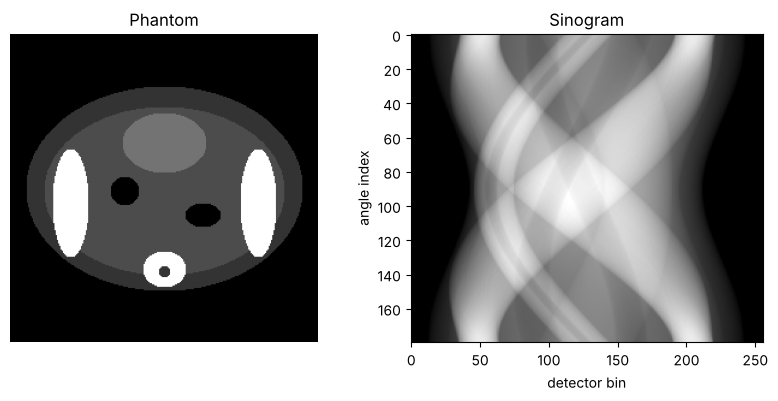

In [2]:
import astra
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.metrics import evaluate
from src.phantom import pelvis_phantom
from src.reconstruction import reconstruct_2d
from src.visualization import show_comparison, show_error_maps

phantom = pelvis_phantom()

# Geometry: parallel beam, 180 angles over 180 degrees, 256 detector bins
n_angles, n_bins = 180, 256
vol_geom = astra.create_vol_geom(256, 256)
angles = np.linspace(0, np.pi, n_angles, endpoint=False)
proj_geom = astra.create_proj_geom("parallel", 1.0, n_bins, angles)
proj_id = astra.create_projector("linear", proj_geom, vol_geom)  # CPU projector
sinogram_id, sinogram = astra.create_sino(phantom, proj_id)       # simulated scan

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("Phantom"); ax[0].axis("off")
ax[1].imshow(sinogram, cmap="gray", aspect="auto"); ax[1].set_title("Sinogram")
ax[1].set_xlabel("detector bin"); ax[1].set_ylabel("angle index")
plt.show()

## 1 · Settings from the course report

In [3]:
def run_all(methods, options=None):
    images, times = {}, {}
    for method, iterations in methods.items():
        opts = (options or {}).get(method)
        images[method], times[method] = reconstruct_2d(
            method, sinogram_id, vol_geom, proj_id, iterations, opts)
    return images, times

def results_table(images, times):
    # BP is not normalised by ASTRA (arbitrary scale), so it is left out of the metrics
    table = pd.DataFrame(evaluate(phantom, {k: v for k, v in images.items() if k != "BP"})).T
    table["time (s)"] = pd.Series(times)
    return table.round(3)

report_methods = {"BP": 1, "FBP": 1, "SIRT": 50, "SART": 1800, "ART": 1000, "CGLS": 100}
report_images, report_times = run_all(report_methods)
report_table = results_table(report_images, report_times)
report_table

,RMSE,PSNR,SSIM,time (s)
FBP,0.024,32.312,0.692,0.087
SIRT,0.053,25.575,0.804,4.623
SART,0.099,20.107,0.449,1.391
ART,0.265,11.538,0.324,0.014
CGLS,0.019,34.291,0.871,10.836


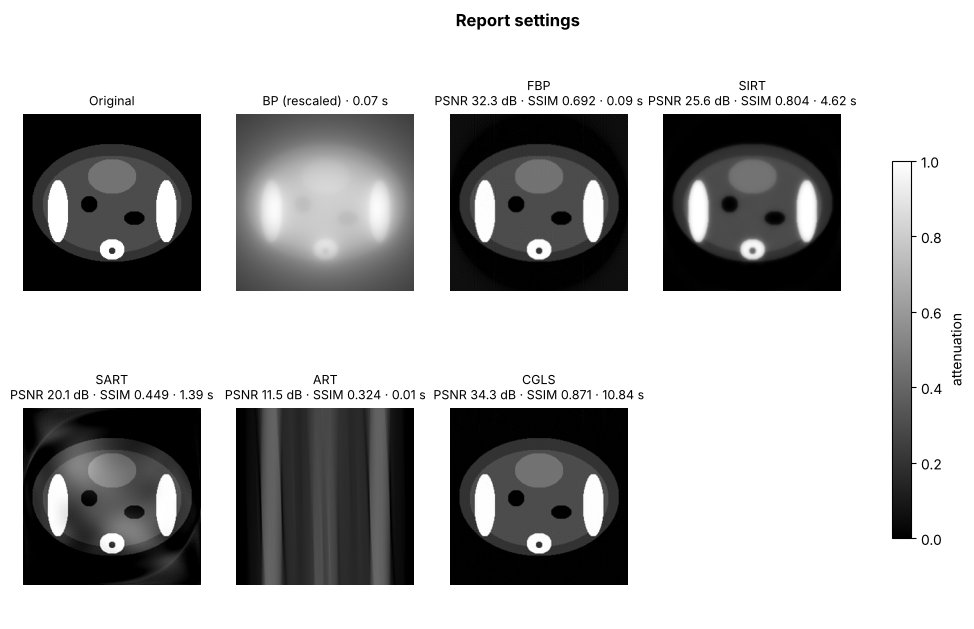

In [4]:
fig = show_comparison(phantom, report_images, report_table.to_dict("index"), report_times,
                      title="Report settings")
plt.show()

## 2 · What went wrong with SART and ART

ASTRA does not count iterations the same way for every algorithm:

| Algorithm | 1 ASTRA iteration = | Report | Real passes over the data |
|---|---|---|---|
| SIRT, CGLS | all 180 angles | 50, 100 | 50, 100 |
| SART | **1 angle** | 1800 | 10 |
| ART | **1 ray** | 1000 | 1000 / (180 × 256) = **0.02** |

* **ART** only used the first ~4 angles. That is why the report shows vertical bands: the algorithm stopped too early, it is not unstable.
* **SART** went through the angles in order (0°, 1°, 2°…). Neighbouring angles carry almost the same information, which leaves a dark arc. Random order fixes it.
* **CGLS** has already converged at ~30 iterations, so 100 is wasted time.

In [5]:
n_rays = n_angles * n_bins
fixed_methods = {"BP": 1, "FBP": 1, "SIRT": 50,
                 "SART": 10 * n_angles,   # 10 full passes
                 "ART": 20 * n_rays,      # 20 full passes
                 "CGLS": 30}
fixed_options = {"SIRT": {"MinConstraint": 0.0},   # attenuation can't be negative
                 "SART": {"ProjectionOrder": "random", "MinConstraint": 0.0},
                 "ART": {"Relaxation": 0.25}}      # smaller steps, more stable
fixed_images, fixed_times = run_all(fixed_methods, fixed_options)
fixed_table = results_table(fixed_images, fixed_times)
fixed_table

,RMSE,PSNR,SSIM,time (s)
FBP,0.024,32.312,0.692,0.037
SIRT,0.052,25.612,0.894,4.979
SART,0.015,36.614,0.948,1.435
ART,0.021,33.704,0.825,8.334
CGLS,0.021,33.674,0.871,3.247


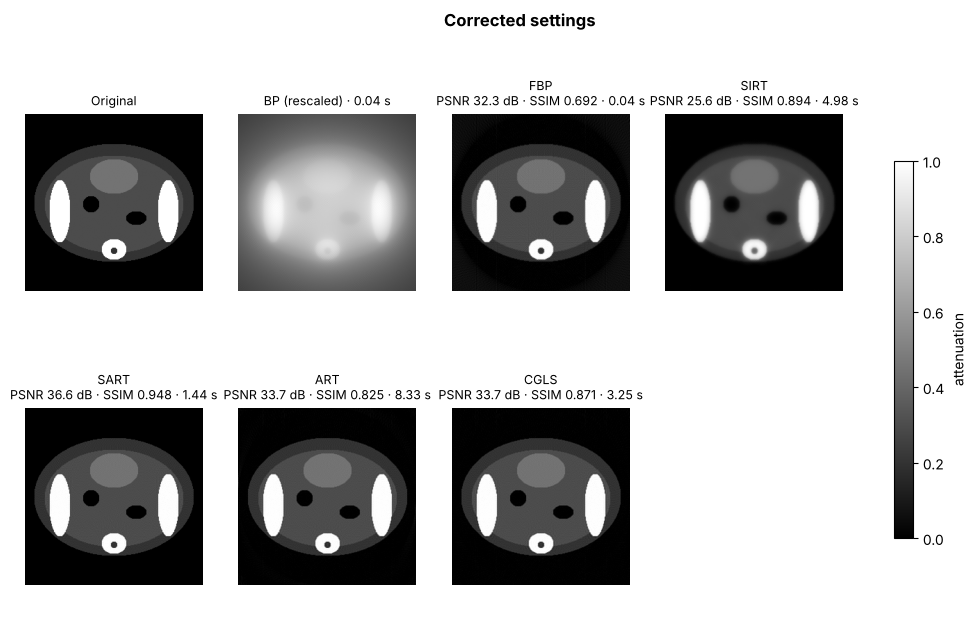

In [6]:
fig = show_comparison(phantom, fixed_images, fixed_table.to_dict("index"), fixed_times,
                      title="Corrected settings")
fig.savefig("docs/figures/2d_corrected.png", dpi=120, bbox_inches="tight")
plt.show()

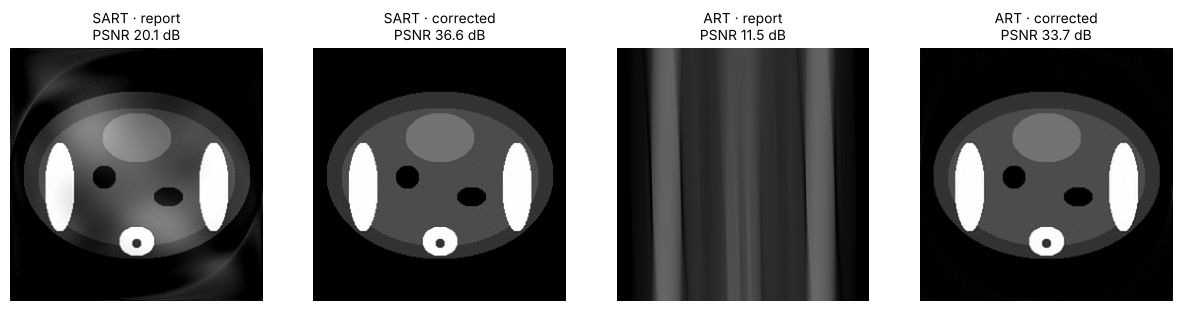

In [7]:
# Before / after for the two methods that changed the most
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
pairs = [("SART · report", report_images["SART"], report_table.loc["SART"]),
         ("SART · corrected", fixed_images["SART"], fixed_table.loc["SART"]),
         ("ART · report", report_images["ART"], report_table.loc["ART"]),
         ("ART · corrected", fixed_images["ART"], fixed_table.loc["ART"])]
for ax, (name, img, row) in zip(axes, pairs):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{name}\nPSNR {row['PSNR']:.1f} dB", fontsize=10)
    ax.axis("off")
fig.savefig("docs/figures/2d_before_after.png", dpi=120, bbox_inches="tight")
plt.show()

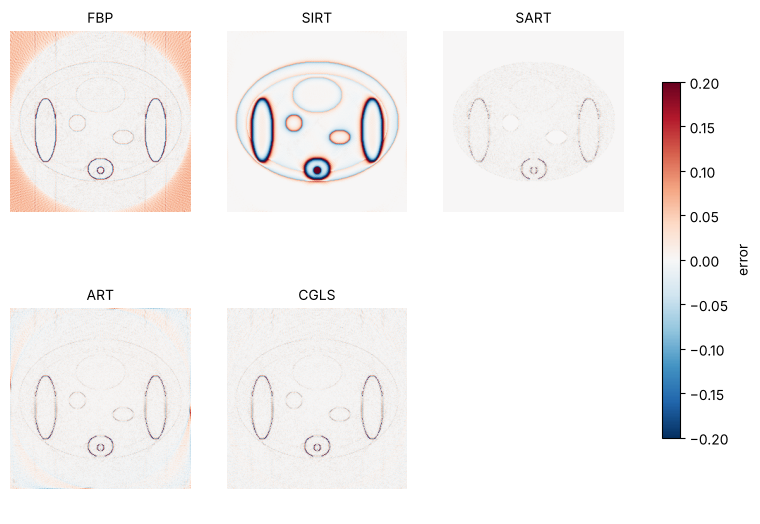

In [8]:
fig = show_error_maps(phantom, fixed_images)
fig.savefig("docs/figures/2d_error_maps.png", dpi=120, bbox_inches="tight")
plt.show()

astra.data2d.delete(sinogram_id)   # free ASTRA memory
astra.projector.delete(proj_id)

## Conclusions
* With the correct number of passes, SART becomes the most accurate method and ART goes from unusable to good.
* FBP gives a good image in about 0.05 s. The iterative methods need seconds, and their quality depends heavily on choosing the iterations well.
* The error maps show where each method fails: SIRT blurs bone edges, while FBP and CGLS leave thin edge errors.